## Setup
Install necessary dependencies.

In [1]:
# Installing the Box2D environment for physics simulation
!pip install gymnasium
!pip install swig
!pip install gymnasium[box2d]
!pip install gymnasium[other]

# Updating the package list and installing necessary packages for the project
!sudo apt-get install -y cmake
# Updating the package list and installing ffmpeg and freeglut3-dev for visualization, xvfb for virtual display
!sudo apt-get install -y ffmpeg freeglut3-dev xvfb

# Installing the Stable Baselines3 library for reinforcement learning along with extra dependencies
!pip install "stable-baselines3[extra]>=2.0.0a4"

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
Sudo is disabled on this machine. To enable it, go to the ]8;;ms-settings:developers\Developer Settings page]8;;\ in the Settings app
Sudo is disabled on this machine. To enable it, go to the ]8;;ms-settings:developers\Developer Settings page]8;;\ in the Settings app


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\riwki\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Import Libraries

In [2]:
# Import necessary libraries and modules
import os
import gymnasium as gym
import stable_baselines3
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.results_plotter import load_results, ts2xy
from stable_baselines3.common.vec_env import VecVideoRecorder, DummyVecEnv
from stable_baselines3.common.torch_layers import BaseFeaturesExtractor
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import torch
from pathlib import Path
import base64
from IPython import display as ipythondisplay

# Print the versions of gymnasium and stable_baselines3 for debugging purposes
print(f"{gym.__version__=}")
print(f"{stable_baselines3.__version__=}")

# Import utility functions for creating Atari environments and stacking frames
from stable_baselines3.common.env_util import make_atari_env
from stable_baselines3.common.vec_env import VecFrameStack


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


gym.__version__='1.4.0'
stable_baselines3.__version__='2.9.0'


In [3]:
# Set up a fake display for rendering videos
os.system("Xvfb :1 -screen 0 1024x768x24 &")
os.environ['DISPLAY'] = ':1'


In [4]:
# Define a callback class for saving models at regular intervals during training
class SaveOnIntervalCallback(BaseCallback):
    def __init__(self, save_interval: int, save_path: str, verbose=1):
        super().__init__(verbose)
        self.save_interval = save_interval
        self.save_path = save_path

    def _on_step(self) -> bool:
        # Save the model every 'save_interval' steps
        if self.num_timesteps % self.save_interval == 0:
            save_file = os.path.join(self.save_path, f'model_{self.num_timesteps}')
            self.model.save(save_file)
            if self.verbose > 0:
                print(f'Saving model to {save_file}.zip')
        return True


In [5]:
# Change the paths based on your directory structure
log_dir = "breakoutPPO/gym/"  # Directory for storing training logs
models_dir = "breakoutPPO/models/"  # Directory for storing models
os.makedirs(log_dir, exist_ok=True)
os.makedirs(models_dir, exist_ok=True)

## Define Custom Feature Extractor and Create PPO Model

In [6]:
# Define a custom CNN feature extractor for processing observations from the environment
class CustomCNN(BaseFeaturesExtractor):
    def __init__(self, observation_space: gym.spaces.Box, features_dim: int = 512):
        super(CustomCNN, self).__init__(observation_space, features_dim)
        # Define the convolutional layers
        self.cnn = nn.Sequential(
            nn.Conv2d(observation_space.shape[0], 32, kernel_size=8, stride=4),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.Flatten(),
        )

        # Compute the size of the output tensor after passing through the CNN
        with torch.no_grad():
            n_flatten = self.cnn(
                torch.as_tensor(observation_space.sample()[None]).float()
            ).shape[1]

        # Define the linear layers that follow the convolutional layers
        self.linear = nn.Sequential(nn.Linear(n_flatten, features_dim), nn.ReLU())

    def forward(self, observations: torch.Tensor) -> torch.Tensor:
        # Process the observations through the CNN and linear layers
        return self.linear(self.cnn(observations))


#### Initial Atari Environment for 'Breakout'

In [8]:
import ale_py
# Initialize the Atari environment with the specified game and configurations
env = make_atari_env("BreakoutNoFrameskip-v4", n_envs=4, seed=0, monitor_dir=log_dir)
# Stack 4 consecutive frames together to provide temporal information
env = VecFrameStack(env, n_stack=4)

#### Initial the PPO model using custon CNN feature extractor

In [9]:
# Initialize the PPO agent with specified parameters
model = PPO(
    env=env,
    policy='CnnPolicy',
    verbose=1,
    clip_range=0.1,
    ent_coef=0.01,
    learning_rate=2.5e-4,
    n_epochs=4,
    n_steps=128,
    vf_coef=0.5,
    batch_size=256,
    ######-----------ADD CUSTOM CNN TO SB3----------------------########
    # Uncomment the next line to use the custom CNN feature extractor
    policy_kwargs={'features_extractor_class': CustomCNN}
    ######------------------------------------------------------########
)


Using cuda device
Wrapping the env in a VecTransposeImage.


## Train the Model

In [ ]:
total_timesteps = 10000000
save_interval = 2000000

save_callback = SaveOnIntervalCallback(
    save_interval,
    models_dir
)

model.learn(
    total_timesteps=total_timesteps,
    callback=save_callback
)

final_model_path = os.path.join(
    models_dir,
    "model_final"
)

model.save(final_model_path)

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 528      |
|    ep_rew_mean     | 0        |
| time/              |          |
|    fps             | 283      |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 512      |
---------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 528           |
|    ep_rew_mean          | 0             |
| time/                   |               |
|    fps                  | 351           |
|    iterations           | 2             |
|    time_elapsed         | 2             |
|    total_timesteps      | 1024          |
| train/                  |               |
|    approx_kl            | 0.00026990287 |
|    clip_fraction        | 0             |
|    clip_range           | 0.1           |
|    entropy_loss         | -1.39         |
|    explained_variance   | -0.00818      |


## Video Recording and Display Functions

In [10]:
# Functions to record videos of the agent playing and display the videos

def show_videos(video_path="", prefix=""):
    """Displays videos from a specified directory."""
    html = []
    for mp4 in Path(video_path).glob("{}*.mp4".format(prefix)):
        video_b64 = base64.b64encode(mp4.read_bytes())
        html.append(
            '''<video alt="{0}" autoplay
                      loop controls style="height: 400px;">
                <source src="data:video/mp4;base64,{1}" type="video/mp4" />
            </video>'''.format(mp4, video_b64.decode('ascii'))
        )
    ipythondisplay.display(ipythondisplay.HTML(data="<br>".join(html)))


def record_video(env_id, model, video_length=500, prefix="", video_folder="breakoutPPO/videos/"):
    eval_env = make_atari_env(env_id, n_envs=1, seed=0, vec_env_cls=DummyVecEnv)  # Create a single Atari environment
    eval_env = VecFrameStack(eval_env, n_stack=4)  # Stack 4 frames together for temporal information
    eval_env = VecVideoRecorder(  # Initialize video recorder
        eval_env,
        video_folder=video_folder,  # Specify folder to save videos
        record_video_trigger=lambda step: step == 0,  # Set trigger to start recording at step 0
        video_length=video_length,  # Set video length
        name_prefix=prefix,  # Set prefix for video filenames
    )
    obs = eval_env.reset()  # Reset the environment to get initial observation
    for _ in range(video_length):  # Loop through for the specified video length
        action, _ = model.predict(obs)  # Predict action based on current observation
        obs, _, _, _ = eval_env.step(action)  # Execute action in the environment
    eval_env.close()  # Close the environment and video recorder

## Record and Display Videos at Different Training Stages

In [11]:
# Create a directory to save videos
os.makedirs("breakoutPPO/videos", exist_ok=True)

# Record a video of the trained agent
# record_video("PongNoFrameskip-v4", model, video_length=1000, prefix='dqn-pong')

# Display the video
import os

def get_model_identifiers(models_dir):
    files = os.listdir(models_dir)

    identifiers = []

    for f in files:
        if f.startswith("model_") and f.endswith(".zip"):
            identifier = f.replace("model_", "").replace(".zip", "")

            if identifier.isdigit():
                identifiers.append(int(identifier))
    return sorted(identifiers)


def find_key_identifiers(identifiers):
    earliest = identifiers[0]
    middle = identifiers[len(identifiers) // 2]
    final = identifiers[-1]
    return earliest, middle, final

def view(models_dir):
    identifiers = get_model_identifiers(models_dir)
    earliest, middle, final = find_key_identifiers(identifiers)

    # Record videos at the beginning, middle, and end of training
    for stage, identifier in zip(["beginning", "middle", "end"], [earliest, middle, final]):
        model_path = os.path.join(models_dir, f'model_{identifier}')
        model = PPO.load(model_path)
        record_video("BreakoutNoFrameskip-v4", model, video_length=5000, prefix=f'ppo-breakout-{stage}')

    # Display the videos
    for stage in ["beginning", "middle", "end"]:
        show_videos("breakoutPPO/videos", prefix=f'ppo-breakout-{stage}')

# Changes the model directory below
models_dir="breakoutPPO/models/"
view(models_dir)

Saving video to d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-beginning-step-0-to-step-5000.mp4
MoviePy - Building video d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-beginning-step-0-to-step-5000.mp4.
MoviePy - Writing video d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-beginning-step-0-to-step-5000.mp4



MoviePy - Done !
MoviePy - video ready d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-beginning-step-0-to-step-5000.mp4
Saving video to d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-middle-step-0-to-step-5000.mp4
MoviePy - Building video d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-middle-step-0-to-step-5000.mp4.
MoviePy - Writing video d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-middle-step-0-to-step-5000.mp4



MoviePy - Done !
MoviePy - video ready d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-middle-step-0-to-step-5000.mp4
Saving video to d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-end-step-0-to-step-5000.mp4
MoviePy - Building video d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-end-step-0-to-step-5000.mp4.
MoviePy - Writing video d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-end-step-0-to-step-5000.mp4



MoviePy - Done !
MoviePy - video ready d:\Project\assignment2\breakoutPPO\videos\ppo-breakout-end-step-0-to-step-5000.mp4


In [12]:
for stage in ["beginning", "middle", "end"]:
    show_videos("breakoutPPO/videos", prefix=f'ppo-breakout-{stage}')

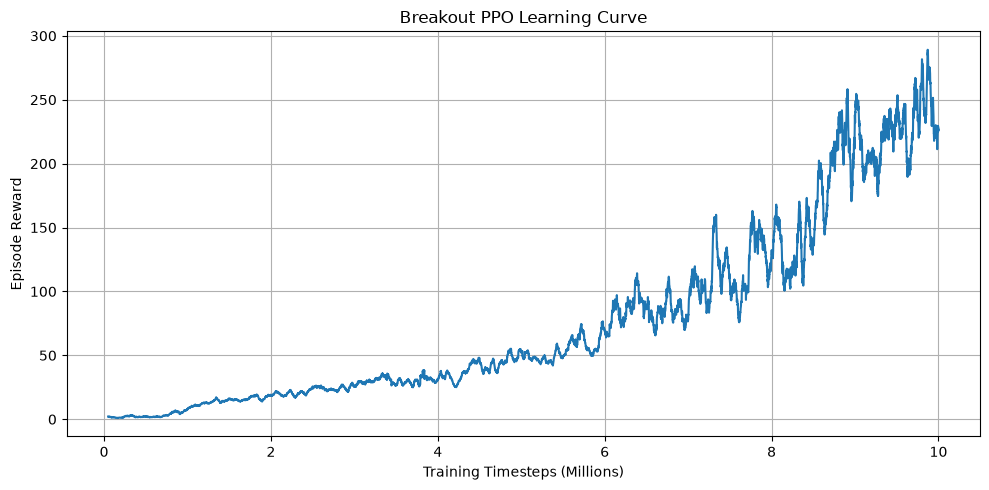

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob

log_dir = "breakoutPPO/gym/"

# Read all 4 Monitor files
files = glob.glob(log_dir + "*.monitor.csv")

dfs = []

for file in files:
    df = pd.read_csv(file, skiprows=1)
    dfs.append(df)

# Combine episodes from all environments
data = pd.concat(dfs, ignore_index=True)

# Sort chronologically using Monitor time
data = data.sort_values("t").reset_index(drop=True)

# Actual SB3 training timesteps
TOTAL_TIMESTEPS = 10000000

# Map completed episodes across actual training progress
data["timesteps"] = np.linspace(
    0,
    TOTAL_TIMESTEPS,
    len(data)
)

# 50-episode moving average
data["reward_smoothed"] = (
    data["r"]
    .rolling(window=50)
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    data["timesteps"] / 1000000,
    data["reward_smoothed"]
)

plt.xlabel("Training Timesteps (Millions)")
plt.ylabel("Episode Reward")
plt.title("Breakout PPO Learning Curve")
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
from stable_baselines3 import PPO
from stable_baselines3.common.evaluation import evaluate_policy

# Load final PPO model
model = PPO.load("breakoutPPO/models/model_final.zip", env=env)

# Evaluate model
mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=20,
    deterministic=True
)

print(f"Average Episode Reward: {mean_reward:.2f}")
print(f"Standard Deviation: {std_reward:.2f}")

Wrapping the env in a VecTransposeImage.
Average Episode Reward: 262.70
Standard Deviation: 110.16
